In [1]:
#use cosmodesi kernel

from abacusnbody.data.read_abacus import read_asdf
import numpy as np
import matplotlib.pyplot as plt
#from abacusnbody.analysis.tpcf_corrfunc import calc_power
import os
from astropy.table import vstack
from pycorr.correlation_function import TwoPointCorrelationFunction, JackknifeTwoPointCounter
from pycorr.twopoint_jackknife import JackknifeTwoPointEstimator
import matplotlib
from astropy.table import Table, vstack, hstack, join
import fitsio
from astropy.cosmology import Planck18 as cosmo
import astropy.units as u

matplotlib.rcParams['mathtext.fontset'] = 'stix'
matplotlib.rcParams['font.family'] = 'STIXGeneral'
plt.rcParams['axes.labelsize'] = 14
plt.rcParams['figure.titlesize'] = 16

## Make a custom catalog with some extra properties from fastspecfit (stellar mass)

In [12]:
def makeBGSTab(file,bgs21_35,cuts = True):
    '''
    Description
        Makes an Astropy table with certain columns from fastspecfit, selecting only BGS galaxies that are also in the r < -21.35 sample
    Arguments
        file: FITS file to read from
        bgs21_35: Astropy table of BGS galaxies (must have at least TARGETID)
    Returns
        Astropy table of BGS galaxies
    '''
    columns = ["TARGETID","ABSMAG01_SDSS_R","LOGMSTAR"]
    tab2 = Table(fitsio.read(file,ext=2,columns=columns))
    columns = ["Z","RA","DEC"]
    tab1 = Table(fitsio.read(file,ext=1,columns=columns))
    columns = ["HALPHA_EW"]
    tab3 = Table(fitsio.read(file,ext=3,columns=columns))
    tabbgs = hstack([tab1,tab2,tab3])
    tabbgs = join(tabbgs,bgs21_35,keys="TARGETID")
    if cuts:
        tabbgs = tabbgs[(tabbgs['Z'] < 0.25) & (tabbgs['LOGMSTAR'] > 10.7)]
    print("finished an nside catalog")
    return tabbgs

In [10]:
#get table of bgs galaxies
bgsdir = "/dvs_ro/cfs/cdirs/desi/survey/catalogs/Y3/LSS/loa-v1/LSScats/v2/nonKP/"
bgsN = Table(fitsio.read(bgsdir+"BGS_BRIGHT_NGC_clustering.dat.fits",columns = ["TARGETID","WEIGHT"]))
bgsS = Table(fitsio.read(bgsdir+"BGS_BRIGHT_SGC_clustering.dat.fits",columns = ["TARGETID","WEIGHT"]))
bgs_clustering = vstack([bgsN,bgsS])

In [4]:
#get table of bgs randoms
bgsdir = "/dvs_ro/cfs/cdirs/desi/survey/catalogs/Y3/LSS/loa-v1/LSScats/v2/nonKP/"
rantabs = []
#for i in range(18):
for i in range(1):
    bgsranN = Table(fitsio.read(bgsdir+"BGS_BRIGHT_NGC_"+str(i)+"_clustering.ran.fits",columns = ["RA","DEC","Z"]))
    bgsranS = Table(fitsio.read(bgsdir+"BGS_BRIGHT_SGC_"+str(i)+"_clustering.ran.fits",columns = ["RA","DEC","Z"]))
    rantabs.append(bgsranN)
    rantabs.append(bgsranS)
bgsrantab = vstack(rantabs)

In [5]:
'''file = '/dvs_ro/cfs/cdirs/desi/vac/dr2/fastspecfit/loa/v1.0/catalogs/fastspec-loa-main-bright-nside1-hp00.fits'
tab2 = Table(fitsio.read(file,ext=2,rows=1))'''

"file = '/dvs_ro/cfs/cdirs/desi/vac/dr2/fastspecfit/loa/v1.0/catalogs/fastspec-loa-main-bright-nside1-hp00.fits'\ntab2 = Table(fitsio.read(file,ext=2,rows=1))"

In [13]:
fsf_dir = '/dvs_ro/cfs/cdirs/desi/vac/dr2/fastspecfit/loa/v1.0/catalogs/'
files = []
#for i in range(12):
for i in range(12):
    files.append(fsf_dir + 'fastspec-loa-main-bright-nside1-hp'+f"{i:02}"+'.fits')

bgstabs = [makeBGSTab(file,bgs_clustering) for file in files]

In [14]:
tabbgs = vstack(bgstabs)

In [15]:
tabbgs['dist'] = cosmo.comoving_distance(tabbgs['Z'])/u.Mpc

In [16]:
tabbgs.write("/pscratch/sd/c/crmiller/bgs_fsf.csv",overwrite=True)

In [ ]:
print(len(tabbgs),len(bgs_clustering))

## Load in data ##

In [2]:
tabbgs = Table.read("/pscratch/sd/c/crmiller/bgs_fsf.csv", format='ascii.csv')

In [3]:
#get table of bgs galaxies
bgsdir = "/dvs_ro/cfs/cdirs/desi/survey/catalogs/Y3/LSS/loa-v1/LSScats/v2/nonKP/"
bgsN = Table(fitsio.read(bgsdir+"BGS_BRIGHT-21.35_NGC_clustering.dat.fits",columns = ["TARGETID","WEIGHT","RA","DEC","Z"]))
bgsS = Table(fitsio.read(bgsdir+"BGS_BRIGHT-21.35_SGC_clustering.dat.fits",columns = ["TARGETID","WEIGHT","RA","DEC","Z"]))
bgs_21_35 = vstack([bgsN,bgsS])
bgs_21_35['dist'] = cosmo.comoving_distance(bgs_21_35['Z'])/u.Mpc
bgs_21_35 = bgs_21_35[bgs_21_35['Z'] < 0.25]

In [12]:
#get table of bgs randoms
bgsdir = "/dvs_ro/cfs/cdirs/desi/survey/catalogs/Y3/LSS/loa-v1/LSScats/v2/nonKP/"
rantabs = []
#for i in range(18):
for i in range(1):
    bgsranN = Table(fitsio.read(bgsdir+"BGS_BRIGHT-21.35_NGC_"+str(i)+"_clustering.ran.fits",columns = ["RA","DEC","Z"]))
    bgsranS = Table(fitsio.read(bgsdir+"BGS_BRIGHT-21.35_SGC_"+str(i)+"_clustering.ran.fits",columns = ["RA","DEC","Z"]))
    bgsranN = bgsranN[bgsranN['Z'] < 0.25]
    bgsranS = bgsranS[bgsranS['Z'] < 0.25]
    rantabs.append(bgsranN)
    rantabs.append(bgsranS)
bgsrantab = vstack(rantabs)
bgsrantab['dist'] = cosmo.comoving_distance(bgsrantab['Z'])/u.Mpc

## Data exploration ##

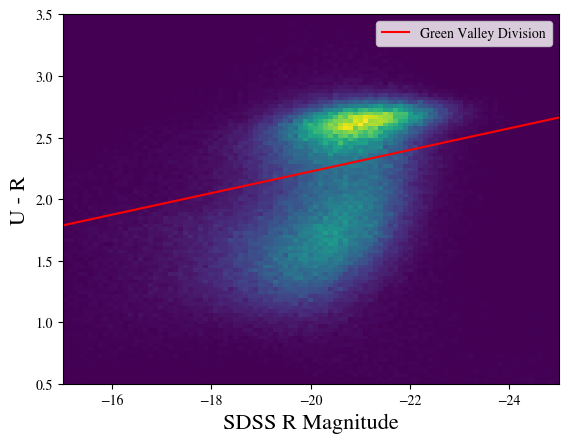

In [8]:
fig, ax = plt.subplots()
plt.hist2d(tabbgs['ABSMAG01_SDSS_R_2'],tabbgs['ABSMAG01_SDSS_U_2']-tabbgs['ABSMAG01_SDSS_R_2'],
           bins=[np.linspace(-25,-15,num=100),np.linspace(0.5,3.5,num=100)])
ax.invert_xaxis()
plt.xlabel("SDSS R Magnitude")
plt.ylabel("U - R")

def pointslopeline(xs,pt,slope):
    ys = (xs - pt[0])*slope + pt[1]
    return ys

xs = np.linspace(-25,-15,num=100)
pt = [-18,2.05]
slope = -(0.35/4)
ys = pointslopeline(xs,pt,slope)
plt.plot(xs,ys,color='red',label = "Green Valley Division")
plt.legend()

'\nxs = np.linspace(-25,-15,num=100)\npt = [-18,2.05]\nslope = -(0.35/4)\nys = pointslopeline(xs,pt,slope)\nplt.plot(xs,ys,color=\'red\',label = "Green Valley Division")\nplt.legend()'

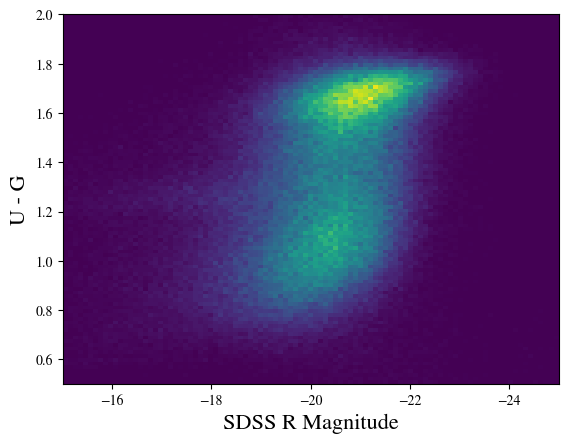

In [9]:
fig, ax = plt.subplots()
plt.hist2d(tabbgs['ABSMAG01_SDSS_R_2'],tabbgs['ABSMAG01_SDSS_U_2']-tabbgs['ABSMAG01_SDSS_G_2'],
           bins=[np.linspace(-25,-15,num=100),np.linspace(0.5,2,num=100)])
ax.invert_xaxis()
plt.xlabel("SDSS R Magnitude")
plt.ylabel("U - G")

def pointslopeline(xs,pt,slope):
    ys = (xs - pt[0])*slope + pt[1]
    return ys
'''
xs = np.linspace(-25,-15,num=100)
pt = [-18,2.05]
slope = -(0.35/4)
ys = pointslopeline(xs,pt,slope)
plt.plot(xs,ys,color='red',label = "Green Valley Division")
plt.legend()'''

'\nxs = np.linspace(-25,-15,num=100)\npt = [-18,2.05]\nslope = -(0.35/4)\nys = pointslopeline(xs,pt,slope)\nplt.plot(xs,ys,color=\'red\',label = "Green Valley Division")\nplt.legend()'

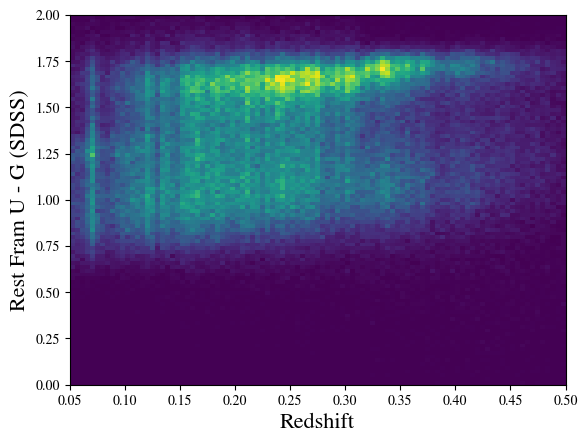

In [10]:
fig, ax = plt.subplots()
plt.hist2d(tabbgs['Z'],tabbgs['ABSMAG01_SDSS_U_2']-tabbgs['ABSMAG01_SDSS_G_2'],
           bins=[np.linspace(0.05,0.5,num=100),np.linspace(0,2,num=100)])
#ax.invert_xaxis()
plt.xlabel("Redshift")
plt.ylabel("Rest Fram U - G (SDSS)")

def pointslopeline(xs,pt,slope):
    ys = (xs - pt[0])*slope + pt[1]
    return ys

'''
xs = np.linspace(-25,-15,num=100)
pt = [-18,2.05]
slope = -(0.35/4)
ys = pointslopeline(xs,pt,slope)
plt.plot(xs,ys,color='red',label = "Green Valley Division")
plt.legend()'''

Text(0, 0.5, 'Rest Fram U - R (SDSS)')

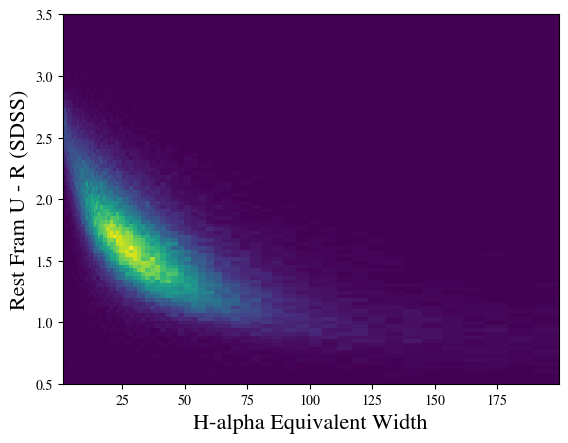

In [12]:
fig, ax = plt.subplots()
'''plt.scatter(tabbgs['HALPHA_EW'],tabbgs['ABSMAG01_SDSS_U_2']-tabbgs['ABSMAG01_SDSS_R_2'],
           s=0.01)'''
plt.hist2d(tabbgs['HALPHA_EW'],tabbgs['ABSMAG01_SDSS_U_2']-tabbgs['ABSMAG01_SDSS_R_2'],
           bins = [np.logspace(0,2.3,num=100),np.linspace(0.5,3.5,num=100)])
#ax.invert_xaxis()
plt.xlabel("H-alpha Equivalent Width")
plt.ylabel("Rest Fram U - R (SDSS)")

Text(0, 0.5, 'Rest Frame U - G (SDSS)')

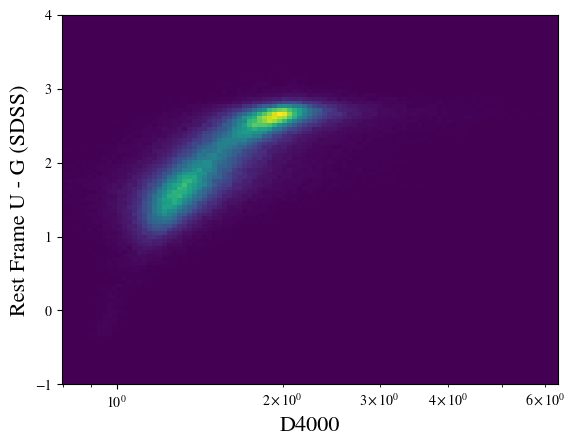

In [13]:
fig, ax = plt.subplots()
plt.hist2d(tabbgs['DN4000_2'],tabbgs['ABSMAG01_SDSS_U_2']-tabbgs['ABSMAG01_SDSS_R_2'],
           bins=[np.logspace(-0.1,0.8,num=100),np.linspace(-1,4,num=100)])
plt.xscale('log')
#ax.invert_xaxis()
plt.xlabel("D4000")
plt.ylabel("Rest Frame U - G (SDSS)")

Text(0, 0.5, 'H-alpha EW')

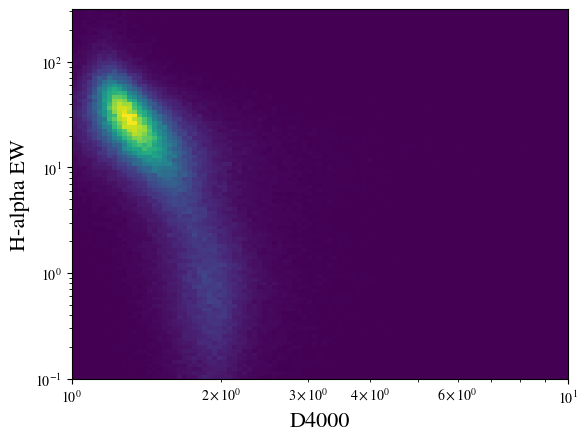

In [14]:
fig, ax = plt.subplots()
plt.hist2d(tabbgs['DN4000_2'],tabbgs['HALPHA_EW'],
           bins=[np.logspace(0,1,num=100),np.logspace(-1,2.5,num=100)])
#plt.xlim(0.1,100)
plt.xscale('log')
#plt.ylim(0.1,500)
plt.yscale('log')
#ax.invert_xaxis()
plt.xlabel("D4000")
plt.ylabel("H-alpha EW")

## Make clustering measurements ##

In [2]:
# split tables by quantiles

#new plan: make a bunch of MASKS rather than saving all the sliced tables

def makeQuantileMasks(table, column, quantiles = [0,10,50,90,100]):
    '''
    Description
        sorts a table and cuts into quantiles by a certain column
    Arguments
        table: Astropy table to cut
        column: string name of column by which to sort
        quantiles: percent quantiles. Must include 0 and 100. If there are n quantiles, you'll end up with n-1 tables.
    '''
    #make the quantiles
    sorted_indices = np.argsort(table[column])
    quantile_indices = quantiles/100*len(table)
    masks = [(sorted_indices >= quantile_indices[i]) and (sorted_indices < quantile_indices[i+1]) for i in range(len(quantiles) - 1)]
    return masks

def makeNDivMasks(table, column, ndivs):
    '''
    Description
        sorts a table and cuts into quantiles by a certain column
    Arguments
        table: Astropy table to cut
        column: string name of column by which to sort
        quantiles: percent quantiles. Must include 0 and 100. If there are n quantiles, you'll end up with n-1 tables.
    '''
    #make the quantiles
    argsorted_indices = np.argsort(table[column])
    sorted_indices = np.argsort(argsorted_indices)
    div_indices = np.arange(ndivs+1)/ndivs*len(table)
    masks = [(sorted_indices >= div_indices[i]) & (sorted_indices < div_indices[i+1]) for i in range(ndivs)]
    return masks

def cutTableValues(table, column, values):
    '''
    '''
    #make the quantiles
    def makeMask(lowerbound, upperbound):
        mask = (table[column] >= lowerbound) and (table[column] < upperbound)
        return mask
    masks = [makeMask(column, values[i], values[i+1]) for i in range(len(values)-1)]
    return masks
'''
def sliceTableRADEC(table, ndivsRA, ndivsDEC):
    def sliceTab(table,ndivs,columnname):
        sortedtab = table.sort(columnname)
        indices = range(ndivs+1)/ndivs*len(table)
        indices = indices.astype(int)
        sliced = [table[indices[i]:indices[i+1]] for i in range(ndivs)]
        return sliced
    slicedRA = sliceTab(table,ndivsRA,"RA")
    slicedRADEC = [sliceTab(tab,ndivsDEC,"DEC") for tab in slicedRA]
    return [tabDEC for tabRA in slicedRADEC for tabDEC in tabRA]'''

def quiltMasks(table,ndivsRA,ndivsDEC):
    ra_masks = makeNDivMasks(table,"RA",ndivsRA)
    indices = np.arange(len(table))
    ra_indices = [indices[mask] for mask in ra_masks]
    dec_masks = [makeNDivMasks(table[mask],"DEC",ndivsDEC) for mask in ra_masks]
    ra_dec_split_indices = [ra_indices[i][dec_masks[i][j]] for i in range(ndivsRA) for j in range(ndivsDEC)]
    def makeMaskFromIndices(indices):
        boolean_mask = np.zeros(len(table), dtype=bool)
        boolean_mask[indices] = True
        return boolean_mask
    masklist = [makeMaskFromIndices(ra_dec_split_indices[i]) for i in range(ndivsRA*ndivsDEC)]
    #we don't care about keeping track of where our divisions are
    return masklist
    

def getpos(tab,mask = None):
    if mask is not None:
        pos = [np.array(tab['RA'][0]),np.array(tab['DEC'][0]),np.array(tab['dist'][0])]
    else:
        pos = [np.array(tab['RA'][mask][0]),np.array(tab['DEC'][mask][0]),np.array(tab['dist'][mask][0])]
    return pos

In [3]:
'''for mask in masks:
    bgstabcut = tabbgs[mask]
    plt.scatter(bgstabcut["RA"],bgstabcut["DEC"],s=0.03)
plt.title("Quilt Jackknife Samples")
plt.xlabel("Right Ascension (Degrees)")
plt.ylabel("Declination (Degrees)")'''

'for mask in masks:\n    bgstabcut = tabbgs[mask]\n    plt.scatter(bgstabcut["RA"],bgstabcut["DEC"],s=0.03)\nplt.title("Quilt Jackknife Samples")\nplt.xlabel("Right Ascension (Degrees)")\nplt.ylabel("Declination (Degrees)")'

In [4]:
def boolMasksToIntLabels(boolmasks):
    samples_int = np.array([(boolmasks[i]).astype(int)*(i+1) for i in range(len(boolmasks))])
    return np.sum(samples_int,axis = 0)

def getJackknifeCounts(reftab, sampletab, refmasks_jack, samplemasks_jack, stringname, samplemask = None, 
                       edges = [np.logspace(-2.5,0.5,num=100),[-40,40]]):
    refpos = getpos(reftab)
    if samplemask is not None:
        samplepos = getpos(sampletab[samplemask])
    else:
        samplepos = getpos(sampletab)
    D2counts = len(samplepos[0])
    #ranpos = getpos(randomtab)
    if samplemask is not None:
        #mask the jackknife mask by the overall mask (e.g., if you are making a luminosity cut, mask the jackknife mask accordingly)
        samplemasks_jack = [samplemasks_jack[i][samplemask] for i in range(len(samplemasks_jack))]
    samples1 = boolMasksToIntLabels(refmasks_jack)
    samples2 = boolMasksToIntLabels(samplemasks_jack)
    #randoms_samples1 = boolMasksToIntLabels(randommasks_jack)
    counter = JackknifeTwoPointCounter('rppi', edges, positions1=refpos, samples1=samples1,
                                     positions2=samplepos, samples2=samples2,
                                     position_type = 'rdd')
    '''
    result = TwoPointCorrelationFunction('rppi', edges, data_positions1=refpos, data_samples1=samples1,
                                     data_positions2=samplepos, data_samples2=samples2,
                                     position_type = 'rdd')
    '''
    counter.save("corrfunc/BGSxquantile_"+stringname)   
    return D2counts

def subsampleCounts(D1tab, D2tab, D1masks_jack, D2masks_jack, D2masks_samples, stringnames):
    D2counts = []
    for i in range(len(D2masks_samples)): 
        D2mask = D2masks_samples[i]
        stringname = stringnames[i]
        D2count = getJackknifeCounts(D1tab,D2tab,D1masks_jack,D2masks_jack,stringname,samplemask = D2mask)
        D2counts.append(D2count)
    return D2counts

In [5]:
def xiTimesRDavisPeebles(D1D2counts,D1R1counts,nD2,nR1,pimax,rcenters):
    xi = [(D1D2counts[j][0]*nR1/(D1R1counts[j][0]*nD2) - 1)*rcenters[j]*2*pimax for j in range(len(D1D2counts))]
    for i in range(len(xi)):
        if xi[i] > 1e10:
            xi[i] = 0
    return np.nan_to_num(np.array(xi),nan = 0)

def xiDavisPeebles(D1D2counts,D1R1counts,nD2,nR1,pimax):
    xi = [(D1D2counts[j][0]*nR1/(D1R1counts[j][0]*nD2) - 1)*2*pimax for j in range(len(D1D2counts))]
    return np.array(xi)

def DavisPeebles2PCFJackknifeCoadd(D1D2names,D1R1name,nD2,nR1,pimax = 40):
    D1D2s = [JackknifeTwoPointCounter.load("corrfunc/"+D1D2names[i]+".npy") for i in range(len(D1D2names))]
    D1R1 = JackknifeTwoPointCounter.load("corrfunc/"+D1R1name+".npy")
    njack = D1R1.nrealizations
    edges = D1D2s[0].edges[0]
    rcenters = np.array([(edges[j]+edges[j+1])/2 for j in range(len(edges)-1)])
    #get overall counts for estimator
    D1D2scounts = np.array([D1D2s[i].wcounts for i in range(len(D1D2names))])
    D1D2counts = np.sum(D1D2scounts,axis = 0)
    D1R1counts = D1R1.wcounts
    nD2tot = np.sum(nD2)
    DavisPeeblesEstimators = xiTimesRDavisPeebles(D1D2counts,D1R1counts,nD2tot,nR1,pimax,rcenters)
    jacksamples = []
    for i in range(D1D2s[0].nrealizations):
        D1D2scounts = np.array([D1D2s[j].realization(i+1).wcounts for j in range(len(D1D2names))])
        D1D2counts = np.sum(D1D2scounts,axis = 0)
        D1R1counts = D1R1.realization(i+1).wcounts
        xiJackknife = xiTimesRDavisPeebles(D1D2counts,D1R1counts,nD2tot,nR1,pimax,rcenters)
        jacksamples.append(xiJackknife)
    #get jackknife error
    differencefromcenter = np.array([jack - DavisPeeblesEstimators for jack in jacksamples])
    SSD = np.sum(differencefromcenter**2, axis = 0)
    jackerror = np.sqrt((njack-1)/njack*SSD)
    return rcenters, DavisPeeblesEstimators, jackerror

In [6]:
#split into quantiles by luminosity
#test our RA-DEC slicing algorithm
#jackknife regions share RA/DEC boundaries (set by bgs_21_35) across all catalogs
import tools
quiltmasks_bgs2135, quiltmasks_bgs, quiltmasks_ran = tools.quiltMasksFromReference(bgs_21_35, [bgs_21_35, tabbgs, bgsrantab], 7, 7)

R_masks = makeNDivMasks(tabbgs, "LOGMSTAR", 100)
D1tab = bgs_21_35
D2tab = tabbgs
D1masks_jack = quiltmasks_bgs2135
D2masks_jack = quiltmasks_bgs
D2masks_samples = R_masks
stringnames = []
for i in range(100):
    stringnames.append("logMstar_quant"+str(i))

NameError: name 'tabbgs' is not defined

In [10]:
D2counts = subsampleCounts(D1tab, D2tab, D1masks_jack, D2masks_jack, D2masks_samples, stringnames)

[11029,
 11029,
 11029,
 11029,
 11029,
 11029,
 11029,
 11029,
 11029,
 11028,
 11029,
 11029,
 11029,
 11029,
 11029,
 11029,
 11029,
 11029,
 11029,
 11028,
 11029,
 11029,
 11029,
 11029,
 11029,
 11029,
 11029,
 11029,
 11029,
 11028,
 11029,
 11029,
 11029,
 11029,
 11029,
 11029,
 11029,
 11029,
 11029,
 11028,
 11029,
 11029,
 11029,
 11029,
 11029,
 11029,
 11029,
 11029,
 11029,
 11028,
 11029,
 11029,
 11029,
 11029,
 11029,
 11029,
 11029,
 11029,
 11029,
 11028,
 11029,
 11029,
 11029,
 11029,
 11029,
 11029,
 11029,
 11029,
 11029,
 11028,
 11029,
 11029,
 11029,
 11029,
 11029,
 11029,
 11029,
 11029,
 11029,
 11028,
 11029,
 11029,
 11029,
 11029,
 11029,
 11029,
 11029,
 11029,
 11029,
 11028,
 11029,
 11029,
 11029,
 11029,
 11029,
 11029,
 11029,
 11029,
 11029,
 11028]

In [13]:
stringname = "BGS-21.35xran"
reftab = bgs_21_35
sampletab = bgsrantab
samplemasks_jack = quiltmasks_ran
refmasks_jack = quiltmasks_bgs2135
rancounts = getJackknifeCounts(reftab, sampletab, refmasks_jack, samplemasks_jack, stringname)

6830683

/tmp/ipykernel_1037739/1621426786.py:2: RuntimeWarning: invalid value encountered in scalar divide
  xi = [(D1D2counts[j][0]*nR1/(D1R1counts[j][0]*nD2) - 1)*rcenters[j]*2*pimax for j in range(len(D1D2counts))]
/tmp/ipykernel_1037739/1621426786.py:2: RuntimeWarning: divide by zero encountered in scalar divide
  xi = [(D1D2counts[j][0]*nR1/(D1R1counts[j][0]*nD2) - 1)*rcenters[j]*2*pimax for j in range(len(D1D2counts))]


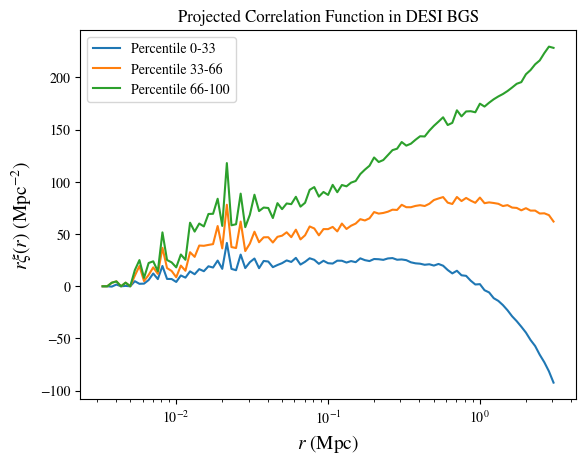

In [10]:
ranges = [[0,33],[33,66],[66,100]]
names = ['Percentile 0-33','Percentile 33-66','Percentile 66-100']
for j in range(len(ranges)):
    D1D2names = []
    for i in np.arange(ranges[j][0],ranges[j][1]):
        D1D2names.append("BGSxquantile_logMstar_quant"+str(i))
    D1R1name = "BGSxquantile_BGS-21.35xran"
    rcenters, DavisPeeblesEstimators, jackerror = tools.DavisPeebles2PCFJackknifeCoadd(D1D2names,D1R1name)
    plt.errorbar(rcenters,DavisPeeblesEstimators,label=names[j])#,yerr = jackerror)

plt.xscale('log')#, yerr = jackerror)
plt.ylabel(r"$r\xi(r)$ (Mpc$^{-2}$)")
plt.xlabel("$r$ (Mpc)")
plt.title("Projected Correlation Function in DESI BGS, Split by Stellar Mass")
plt.legend()

Text(0.5, 0, '$r$ (Mpc)')

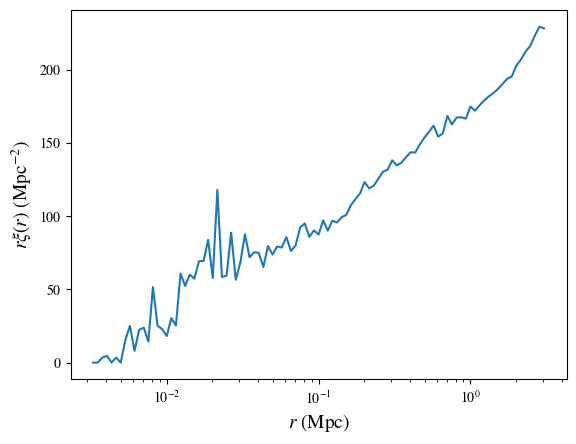

In [48]:
rcenters

[np.float64(0.0032765421710312164),
 np.float64(0.0035133287715313154),
 np.float64(0.003767227281858825),
 np.float64(0.0040394743322002625),
 np.float64(0.00433139592057038),
 np.float64(0.0046444138711768486),
 np.float64(0.00498005275951301),
 np.float64(0.005339947337907859),
 np.float64(0.005725850497699881),
 np.float64(0.006139641806815081),
 np.float64(0.006583336664332052),
 np.float64(0.007059096116622036),
 np.float64(0.007569237382874171),
 np.float64(0.008116245141271176),
 np.float64(0.008702783630785627),
 np.float64(0.009331709627539417),
 np.float64(0.01000608635892868),
 np.float64(0.010729198423283844),
 np.float64(0.011504567787732106),
 np.float64(0.012335970942180955),
 np.float64(0.01322745729297244),
 np.float64(0.014183368885795751),
 np.float64(0.015208361553919867),
 np.float64(0.016307427594750255),
 np.float64(0.017485920085157345),
 np.float64(0.01874957895400618),
 np.float64(0.02010455893887543),
 np.float64(0.021557459563130776),
 np.float64(0.02311535

In [49]:
DavisPeeblesEstimators

array([0.00000000e+000, 1.79769313e+308, 3.43175718e+000, 4.68049040e+000,
       1.79769313e+308, 3.46376669e+000, 1.79769313e+308, 1.54476730e+001,
       2.50750841e+001, 8.02654131e+000, 2.23064933e+001, 2.39185216e+001,
       1.43959385e+001, 5.16288765e+001, 2.51758579e+001, 2.28853533e+001,
       1.81291712e+001, 3.04473019e+001, 2.53883792e+001, 6.08988196e+001,
       5.23811082e+001, 6.01050386e+001, 5.73273280e+001, 6.92600920e+001,
       6.94407569e+001, 8.38514615e+001, 5.78381645e+001, 1.18017126e+002,
       5.84479017e+001, 5.94209774e+001, 8.87348718e+001, 5.66342500e+001,
       6.85070584e+001, 8.77013636e+001, 7.20423294e+001, 7.54240061e+001,
       7.49887192e+001, 6.53751437e+001, 7.96347259e+001, 7.38790583e+001,
       7.93226987e+001, 7.86694877e+001, 8.57254853e+001, 7.62803314e+001,
       7.99961831e+001, 9.23766350e+001, 9.50270266e+001, 8.59043009e+001,
       9.03422041e+001, 8.74845282e+001, 9.71634105e+001, 9.01026737e+001,
       9.70043776e+001, 9